# 09 · Local order and the price of spatial specificity

A grid of local Q-tensors preserves position. It also makes the comparison sensitive to the coordinate origin. We compare grid sizes 1, 2, 4, 8 and 16 on the same image, then translate it through every integer horizontal displacement.

## Setup
Stage 2 holds the motif inventory fixed and changes spatial organization.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.fft import dctn
from observables.core import moments,relative_distance
from observables.images import tiled_orientation
from observables.spatial import *
OUT=ROOT/'results'/'stage2'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.figsize':(8,3.8),'figure.dpi':110,
 'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
images={name:mosaic(name) for name in LAYOUTS}
gallery=[representations(image) for image in images.values()]

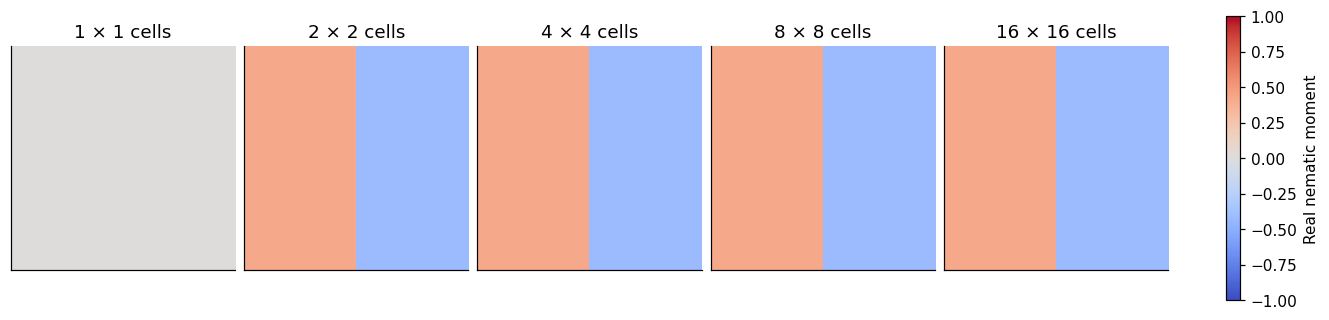

In [3]:
a=images['domains']
fig,axes=plt.subplots(1,5,figsize=(12,2.8))
for ax,g in zip(axes,[1,2,4,8,16]):
    field=tiled_orientation(a,g)[:,1].reshape(g,g)
    im=ax.imshow(field.real,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_title(f'{g} × {g} cells');ax.set_xticks([]);ax.set_yticks([])
fig.colorbar(im,ax=axes,label='Real nematic moment')
show('09_grid_scales')

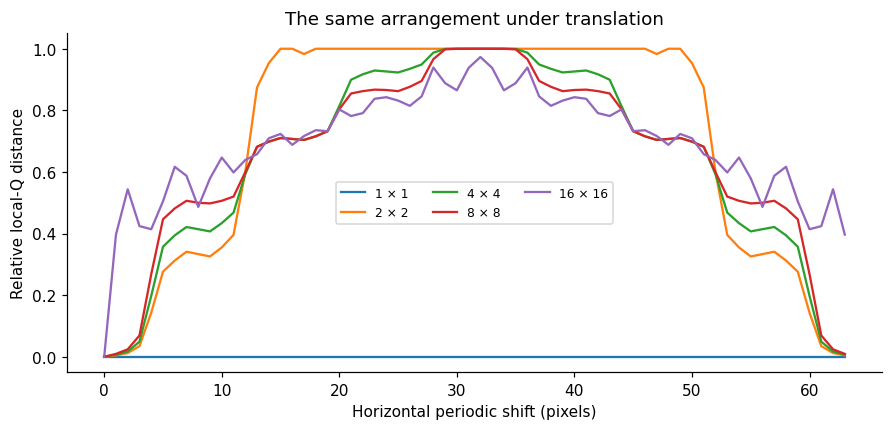

grid,1,2,4,8,16
shift_px,,,,,
0,0.0,0.000,0.000,0.000,0.000
3,0.0,0.035,0.049,0.069,0.424
8,0.0,0.333,0.414,0.500,0.487
16,0.0,1.000,0.707,0.707,0.688
32,0.0,1.000,1.000,1.000,0.973


In [5]:
rows=[]
for dx in range(64):
    shifted=np.roll(a,dx,axis=1)
    for grid in [1,2,4,8,16]:
        reference=tiled_orientation(a,grid)[:,1]
        within=relative_distance(reference,tiled_orientation(shifted,grid)[:,1])
        between=relative_distance(reference,tiled_orientation(images['checker'],grid)[:,1])
        rows.append((dx,grid,within,between))
sweep=pd.DataFrame(rows,columns=['shift_px','grid','same_layout_distance','checker_distance'])
sweep.to_csv(OUT/'translation_sweep.csv',index=False)
fig,ax=plt.subplots()
for grid,g in sweep.groupby('grid'):
    ax.plot(g.shift_px,g.same_layout_distance,label=f'{grid} × {grid}')
ax.set(xlabel='Horizontal periodic shift (pixels)',ylabel='Relative local-Q distance',title='The same arrangement under translation')
ax.legend(ncol=3,fontsize=8);show('09_translation_sweep')
display(sweep[sweep.shift_px.isin([0,3,8,16,32])].pivot(index='shift_px',columns='grid',values='same_layout_distance').round(3))

## Fixed-grid patches can acquire false spatial sensitivity
A shift by a whole patch preserves the aligned patch multiset. A fractional-patch shift changes how the image is partitioned. Variation in a pooled patch Q score after that shift can come from the new partition, even when the physical arrangement merely moved.

In [7]:
rows=[]
for dx in [0,1,3,7,8,16,32]:
    x=np.roll(a,dx,axis=1)
    mean,q=patch_moments(x);m0,q0=patch_moments(a)
    rows.append((dx,relative_distance(m0,mean),relative_distance(q0,q)))
display(pd.DataFrame(rows,columns=['shift_px','patch_mean_distance','patch_Q_distance']).round(5))

,shift_px,patch_mean_distance,patch_Q_distance
0,0,0.00000,0.00000
1,1,0.56795,0.55587
2,3,0.63342,0.69576
3,7,0.56795,0.55587
4,8,0.00000,0.00000
5,16,0.00000,0.00000
6,32,0.00000,0.00000


## Interpretation
Increasing grid resolution offers additional positional detail. Whether it improves recognition depends on how positions are aligned. A coarse grid can lose an arrangement; a fine grid can penalize a harmless displacement. The next notebook compares explicit alignment with translation-invariant correlations.